# LAB CHƯƠNG 2 — XỬ LÝ ẢNH SỐ

Notebook được sắp xếp theo đúng 3 phần của đề bài. Mỗi mục gồm: **mục đích → xử lý → hiển thị kết quả → chỉ số/biểu đồ → nhận xét ngắn**.

**Ảnh đầu vào:** tự chép ảnh vào thư mục `input/` nằm cạnh notebook. Không tải ảnh từ Internet. Nếu có nhiều ảnh, chọn tên ảnh tại `IMAGE_FILENAME` ở phần 1.

**Kết quả:** ảnh và biểu đồ được lưu trong thư mục `results/`.

## 0. Thư viện và thiết lập

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import time
from pathlib import Path

SEED = 42
INPUT_DIR = Path("input")
OUTPUT_DIR = Path("results")
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.5.4


## 1. Đọc ảnh do người dùng cung cấp

Đặt ảnh trong `input/`. Nếu chỉ có một ảnh hợp lệ, notebook tự chọn ảnh đó. Nếu có nhiều ảnh, điền tên file vào `IMAGE_FILENAME`.

Ảnh: images.jpg | Kích thước: 554 x 554 | dtype: uint8


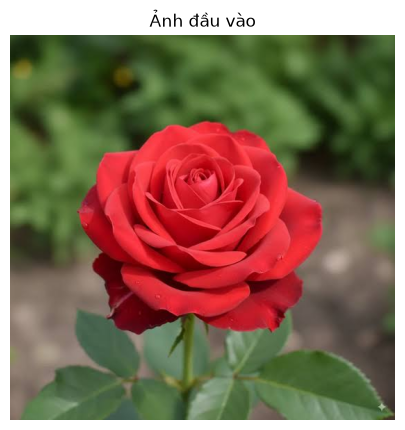

In [2]:
IMAGE_FILENAME = None  # Ví dụ: "anh_cua_toi.jpg"

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
image_files = sorted(p for p in INPUT_DIR.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions)

if not image_files:
    raise FileNotFoundError("Thư mục input/ chưa có ảnh. Hãy chép ảnh của bạn vào đây.")

if IMAGE_FILENAME is None:
    if len(image_files) != 1:
        raise ValueError("Có nhiều ảnh trong input/. Hãy gán IMAGE_FILENAME bằng tên ảnh muốn dùng.")
    image_path = image_files[0]
else:
    image_path = INPUT_DIR / IMAGE_FILENAME
    if not image_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh: {image_path}")

image = cv2.imdecode(np.fromfile(str(image_path), dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Không đọc được ảnh: {image_path}")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
height, width = gray.shape
print(f"Ảnh: {image_path.name} | Kích thước: {width} x {height} | dtype: {image.dtype}")
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Ảnh đầu vào")
plt.axis("off")
plt.show()

## Hàm hỗ trợ hiển thị, lưu ảnh và đo chỉ số

Các chỉ số được chọn theo đúng mục tiêu từng phép biến đổi:
- **Mean intensity:** độ sáng trung bình.
- **Standard deviation (Std):** độ phân tán mức xám, dùng tham khảo độ tương phản.
- **Laplacian variance:** độ sắc nét/độ chi tiết cạnh; giá trị lớn thường biểu thị nhiều chi tiết tần số cao hơn, nhưng cũng có thể tăng do nhiễu.
- **Edge density:** tỷ lệ pixel được phân loại là cạnh theo ngưỡng đã chọn.
- **MSE/PSNR:** sai khác so với ảnh tham chiếu; chỉ dùng để so sánh định lượng khi có ảnh sạch tham chiếu.

In [3]:
def bgr_to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def show_grid(items, cols=2, figsize=(14, 9)):
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, img, *cmap) in zip(axes.flat, items):
        ax.imshow(bgr_to_rgb(img), cmap=cmap[0] if cmap else None,
                  vmin=0 if cmap else None, vmax=255 if cmap else None)
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def save_img(name, img):
    path = OUTPUT_DIR / name
    ok, encoded = cv2.imencode(path.suffix or ".png", img)
    if not ok:
        raise IOError(f"Không lưu được {path}")
    encoded.tofile(str(path))

def image_metrics(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    return {
        "Độ sáng TB": float(np.mean(g)),
        "Độ tương phản (Std)": float(np.std(g)),
        "Độ sắc nét (Laplacian Var)": float(cv2.Laplacian(g, cv2.CV_64F).var())
    }

def plot_metric_bars(labels, values, title, ylabel):
    plt.figure(figsize=(9, 4))
    bars = plt.bar(labels, values)
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.show()


def show_table(headers, rows, title=None, decimals=2):
    """Hiển thị bảng số liệu gọn, không cần cài thêm pandas."""
    formatted = []
    for row in rows:
        formatted.append([
            (f"{value:.{decimals}f}" if isinstance(value, (int, float, np.integer, np.floating)) else str(value))
            for value in row
        ])
    fig, ax = plt.subplots(figsize=(max(7, len(headers) * 2), 0.65 + 0.42 * (len(rows) + 1)))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    table = ax.table(cellText=formatted, colLabels=headers, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)
    plt.tight_layout()
    plt.show()


def show_gray_histogram(named_images, title):
    plt.figure(figsize=(10, 4))
    for label, img in named_images:
        g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
        hist = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel()
        plt.plot(hist, label=label, linewidth=1.5)
    plt.title(title)
    plt.xlabel("Mức xám (0–255)")
    plt.ylabel("Số pixel")
    plt.xlim(0, 255)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

# I. TOÁN TỬ ĐIỂM ẢNH

Thực hiện đúng 4 yêu cầu: thay đổi độ sáng, thay đổi độ tương phản, âm bản và cắt ngưỡng.

### I.1. Thay đổi độ sáng

Cộng/trừ hằng số `C` cho từng pixel: `g(x,y) = clip(f(x,y) ± C, 0, 255)`. Biểu đồ mức xám cho thấy histogram dịch sang phải khi tăng sáng và sang trái khi giảm sáng.

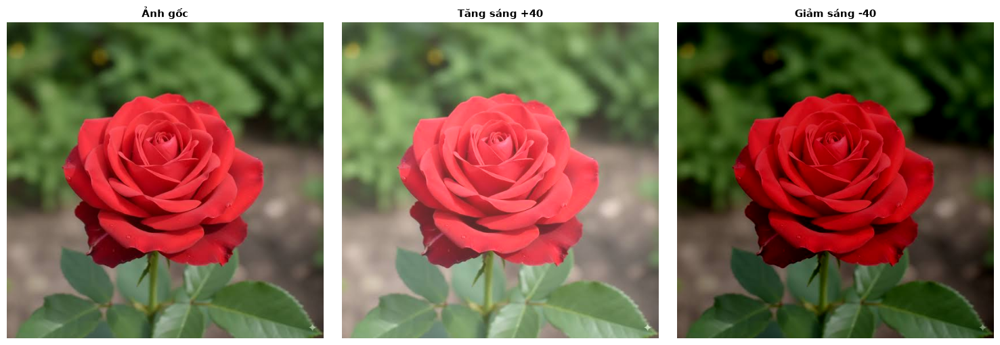

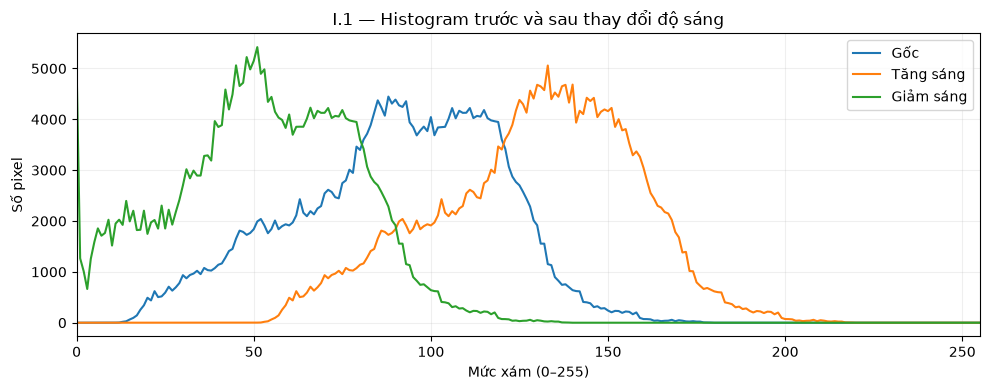

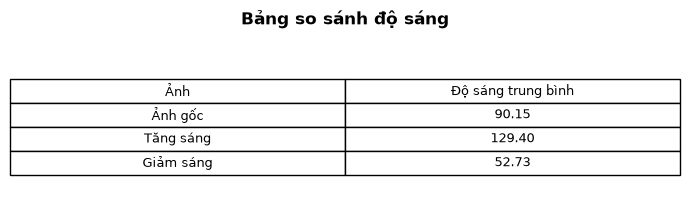

In [4]:
C = 40
bright = np.clip(image.astype(np.int16) + C, 0, 255).astype(np.uint8)
dark = np.clip(image.astype(np.int16) - C, 0, 255).astype(np.uint8)

show_grid([("Ảnh gốc", image), (f"Tăng sáng +{C}", bright),
           (f"Giảm sáng -{C}", dark)], cols=3, figsize=(15, 5))
show_gray_histogram([("Gốc", image), ("Tăng sáng", bright), ("Giảm sáng", dark)],
                    "I.1 — Histogram trước và sau thay đổi độ sáng")
show_table(["Ảnh", "Độ sáng trung bình"], [
    ("Ảnh gốc", image_metrics(image)["Độ sáng TB"]),
    ("Tăng sáng", image_metrics(bright)["Độ sáng TB"]),
    ("Giảm sáng", image_metrics(dark)["Độ sáng TB"])
], "Bảng so sánh độ sáng")
save_img("I1_tang_sang.png", bright)
save_img("I1_giam_sang.png", dark)

**Cách nhận xét:** ảnh tăng sáng có độ sáng trung bình lớn hơn ảnh gốc; ảnh giảm sáng có độ sáng trung bình nhỏ hơn. Histogram tương ứng dịch phải/trái. Các pixel chạm 0 hoặc 255 là hiện tượng clipping.

### I.2. Thay đổi độ tương phản

Theo yêu cầu đề bài, nhân giá trị mỗi pixel với hệ số `alpha`: `g(x,y) = clip(alpha × f(x,y), 0, 255)`. `alpha > 1` tăng tương phản theo phép nhân; `0 < alpha < 1` làm giảm mức cường độ.

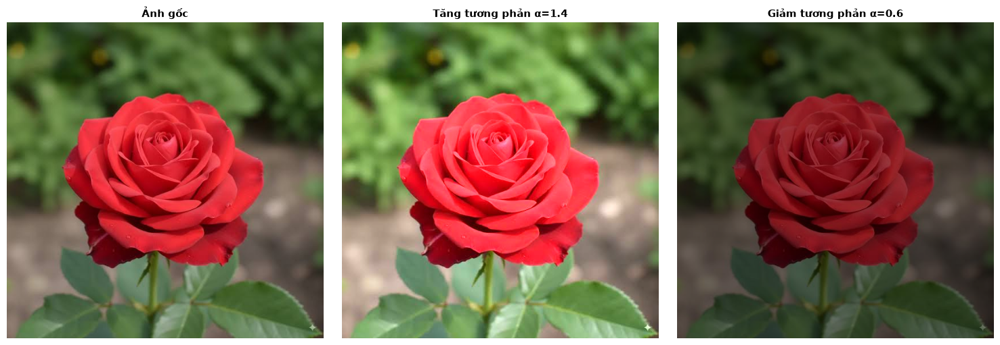

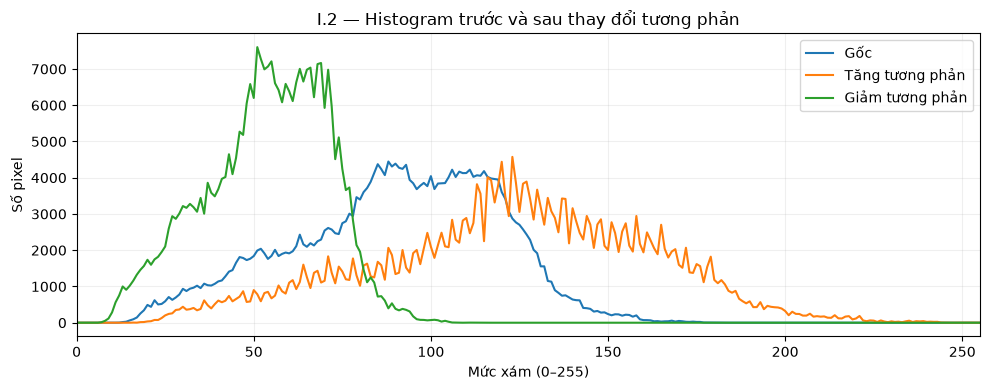

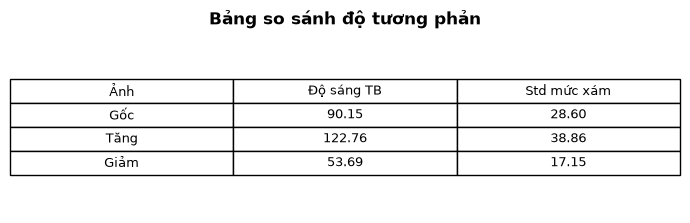

In [5]:
alpha_up, alpha_down = 1.4, 0.6
contrast_up = np.clip(image.astype(np.float32) * alpha_up, 0, 255).astype(np.uint8)
contrast_down = np.clip(image.astype(np.float32) * alpha_down, 0, 255).astype(np.uint8)

show_grid([("Ảnh gốc", image), (f"Tăng tương phản α={alpha_up}", contrast_up),
           (f"Giảm tương phản α={alpha_down}", contrast_down)],
          cols=3, figsize=(15, 5))
show_gray_histogram([("Gốc", image), ("Tăng tương phản", contrast_up),
                     ("Giảm tương phản", contrast_down)],
                    "I.2 — Histogram trước và sau thay đổi tương phản")
contrast_rows = []
for name, img in [("Gốc", image), ("Tăng", contrast_up), ("Giảm", contrast_down)]:
    m = image_metrics(img)
    contrast_rows.append([name, m["Độ sáng TB"], m["Độ tương phản (Std)"]])
show_table(["Ảnh", "Độ sáng TB", "Std mức xám"], contrast_rows,
           "Bảng so sánh độ tương phản")
save_img("I2_tang_tuong_phan.png", contrast_up)
save_img("I2_giam_tuong_phan.png", contrast_down)

**Cách nhận xét:** so sánh độ lệch chuẩn (Std) và độ trải rộng histogram. Std lớn hơn thường biểu thị mức xám phân tán rộng hơn. Do phép nhân trực tiếp có clipping, độ sáng trung bình cũng có thể thay đổi; đây đúng với cách biến đổi được nêu trong đề.

### I.3. Biến đổi âm bản

Công thức: `g(x,y) = 255 - f(x,y)`. Histogram của ảnh âm bản là histogram ảnh gốc đảo theo trục mức xám.

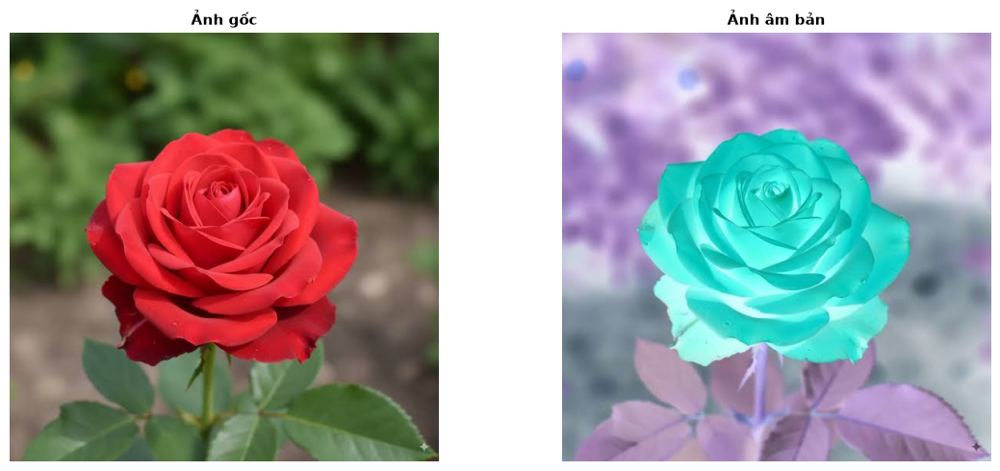

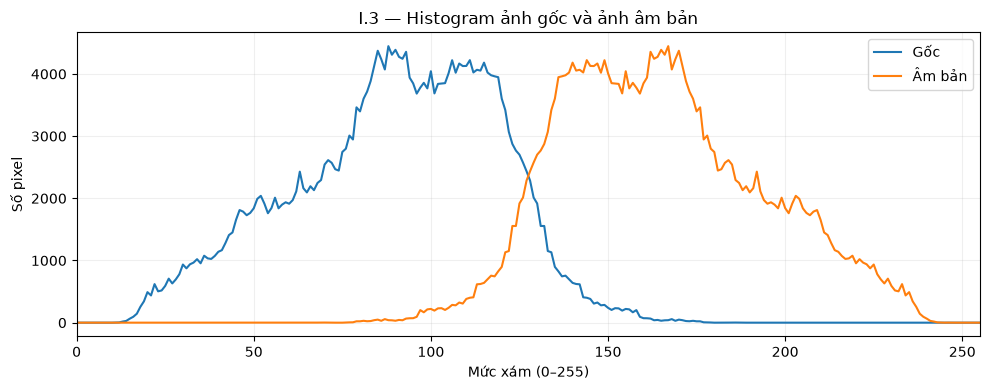

Kiểm tra công thức âm bản: True


In [6]:
negative = 255 - image
show_grid([("Ảnh gốc", image), ("Ảnh âm bản", negative)], cols=2, figsize=(12, 5))
show_gray_histogram([("Gốc", image), ("Âm bản", negative)],
                    "I.3 — Histogram ảnh gốc và ảnh âm bản")
print("Kiểm tra công thức âm bản:", np.array_equal(negative, 255 - image))
save_img("I3_am_ban.png", negative)

**Cách nhận xét:** vùng sáng ở ảnh gốc trở thành vùng tối ở ảnh âm bản và ngược lại. Histogram phản chiếu quanh mức xám 127.5.

### I.4. Cắt ngưỡng tạo ảnh nhị phân

Pixel có mức xám lớn hơn ngưỡng `T` được gán 255 (trắng), còn lại gán 0 (đen).

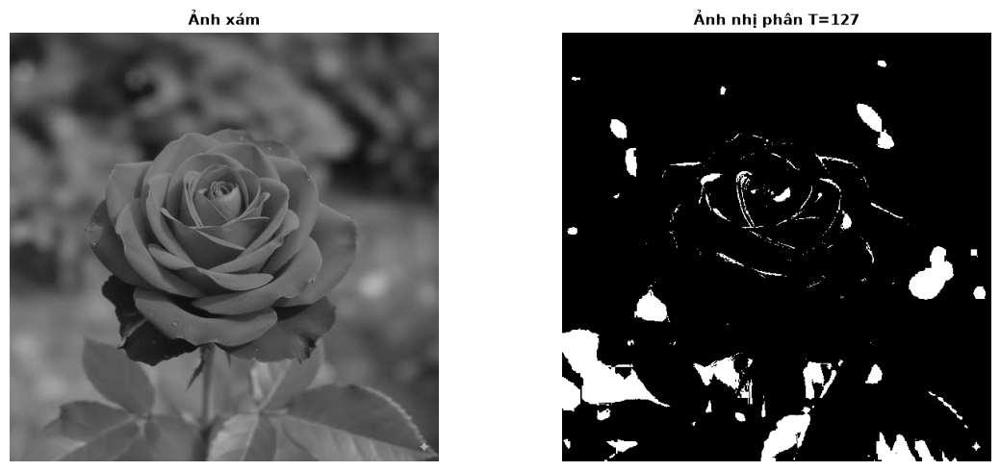

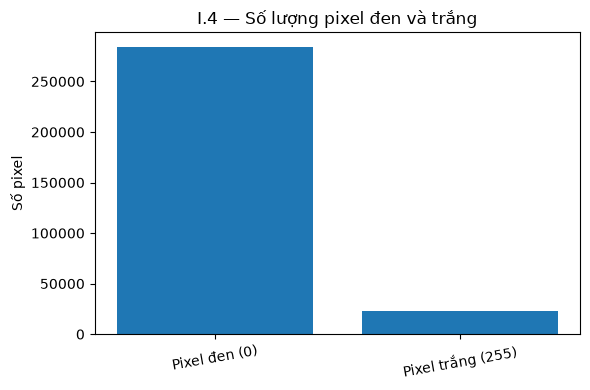

Tỷ lệ pixel trắng: 7.34%


In [7]:
T = 127
_, binary = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY)
show_grid([("Ảnh xám", gray, "gray"), (f"Ảnh nhị phân T={T}", binary, "gray")],
          cols=2, figsize=(12, 5))
counts = {"Pixel đen (0)": int(np.count_nonzero(binary == 0)),
          "Pixel trắng (255)": int(np.count_nonzero(binary == 255))}
plt.figure(figsize=(6, 4))
plt.bar(counts.keys(), counts.values())
plt.title("I.4 — Số lượng pixel đen và trắng")
plt.ylabel("Số pixel")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()
print("Tỷ lệ pixel trắng: {:.2f}%".format(100 * np.mean(binary == 255)))
save_img("I4_nhi_phan.png", binary)

**Cách nhận xét:** ảnh đầu ra chỉ có hai mức 0 và 255. Tỷ lệ pixel trắng/đen cho biết ngưỡng đang phân chia ảnh thành hai vùng như thế nào.

# II. LỌC TUYẾN TÍNH

Theo đề bài gồm 3 nội dung: Mean Filter, Gaussian Filter và làm sắc nét. Mỗi phép lọc được so sánh với ảnh gốc bằng ảnh kết quả, histogram và chỉ số phù hợp.

### II.1. Lọc trung bình (Mean Filter)

Kernel trung bình 5×5 có các phần tử bằng `1/25`. Bộ lọc thay mỗi pixel bằng trung bình các pixel trong vùng lân cận.

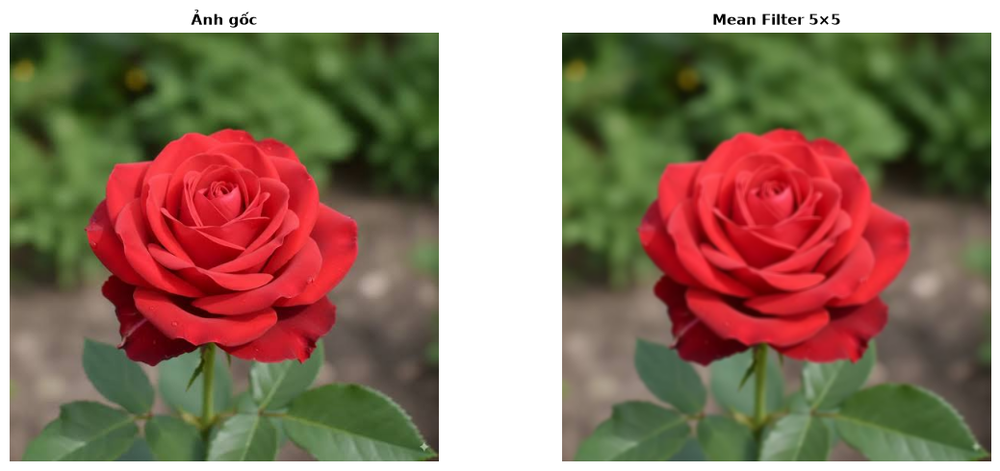

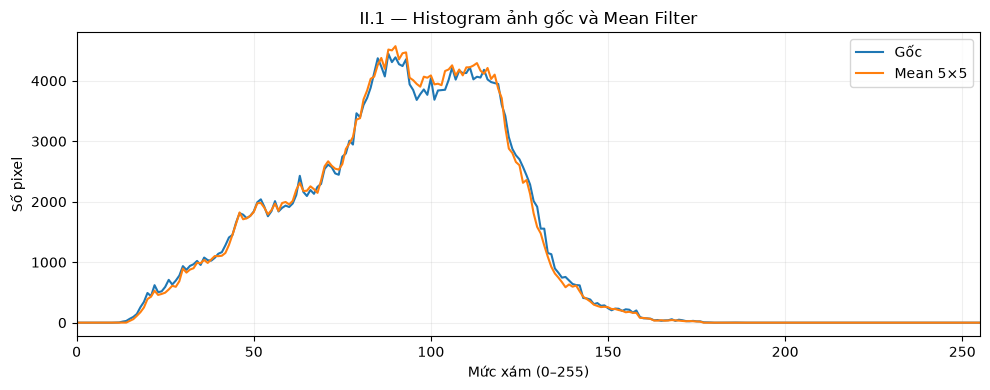

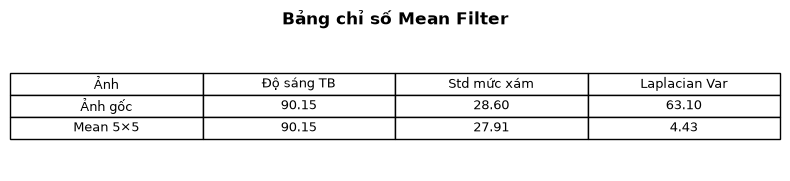

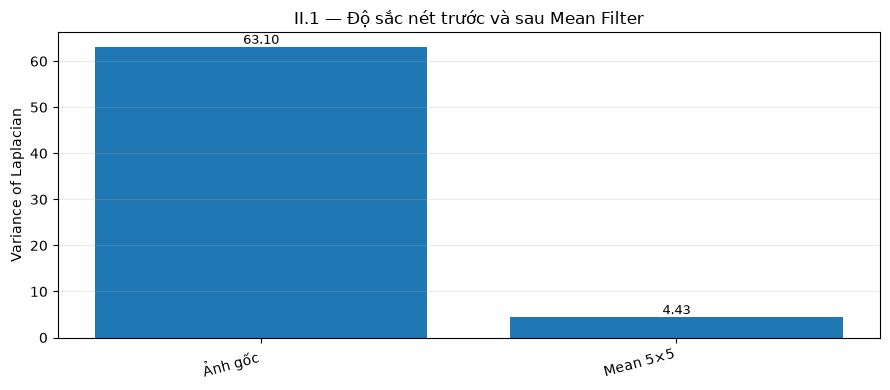

In [8]:
mean_img = cv2.blur(image, (5, 5))
show_grid([("Ảnh gốc", image), ("Mean Filter 5×5", mean_img)], cols=2, figsize=(12, 5))
show_gray_histogram([("Gốc", image), ("Mean 5×5", mean_img)],
                    "II.1 — Histogram ảnh gốc và Mean Filter")
mean_rows = [
    ["Ảnh gốc", *image_metrics(image).values()],
    ["Mean 5×5", *image_metrics(mean_img).values()]
]
show_table(["Ảnh", "Độ sáng TB", "Std mức xám", "Laplacian Var"],
           mean_rows, "Bảng chỉ số Mean Filter")
plot_metric_bars(["Ảnh gốc", "Mean 5×5"],
                 [image_metrics(image)["Độ sắc nét (Laplacian Var)"],
                  image_metrics(mean_img)["Độ sắc nét (Laplacian Var)"]],
                 "II.1 — Độ sắc nét trước và sau Mean Filter", "Variance of Laplacian")
save_img("II1_mean_5x5.png", mean_img)

**Cách nhận xét:** Mean Filter làm mượt bằng cách lấy trung bình đều. Độ sắc nét (Laplacian variance) thường giảm vì các chi tiết/cạnh bị làm mờ; vùng nhiễu nhỏ cũng có thể giảm.

### II.2. Lọc Gaussian

Gaussian dùng trọng số lớn hơn ở gần tâm kernel, nên làm mờ tự nhiên hơn lọc trung bình.

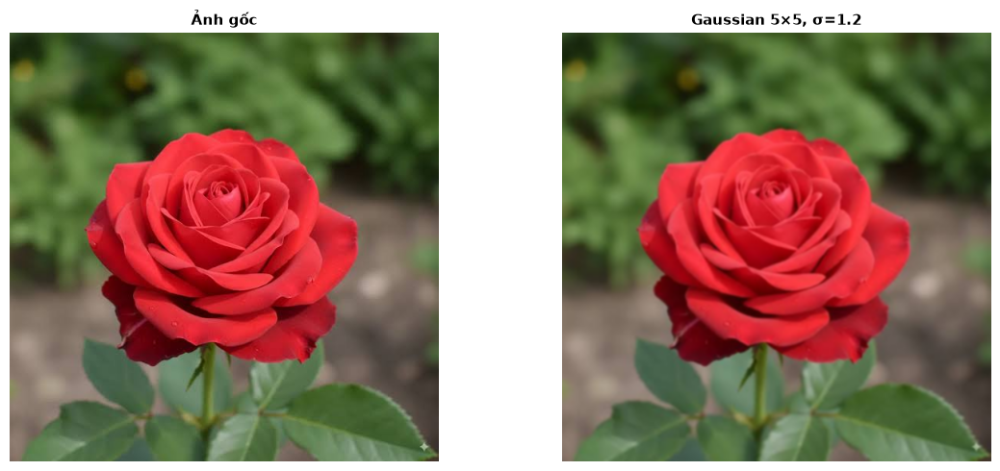

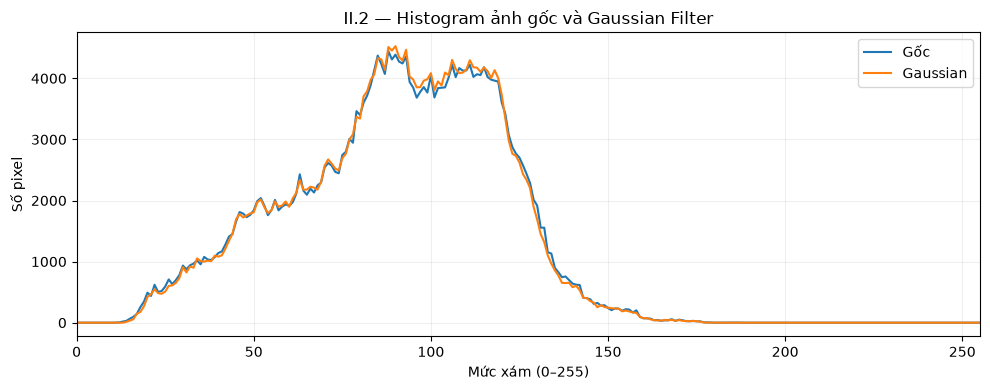

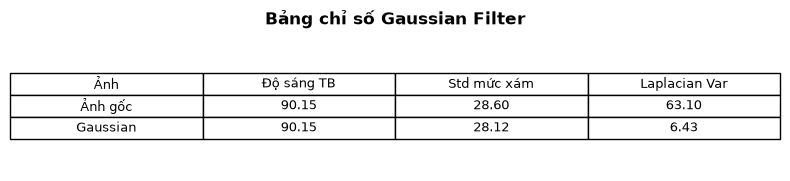

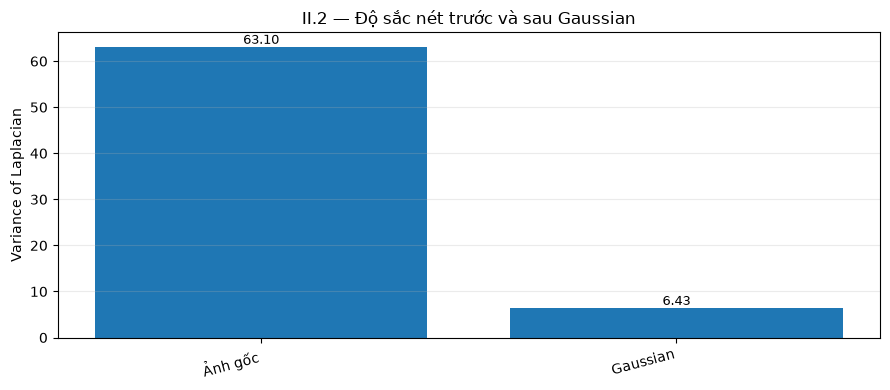

In [9]:
gaussian_img = cv2.GaussianBlur(image, (5, 5), sigmaX=1.2)
show_grid([("Ảnh gốc", image), ("Gaussian 5×5, σ=1.2", gaussian_img)],
          cols=2, figsize=(12, 5))
show_gray_histogram([("Gốc", image), ("Gaussian", gaussian_img)],
                    "II.2 — Histogram ảnh gốc và Gaussian Filter")
g0, g1 = image_metrics(image), image_metrics(gaussian_img)
show_table(["Ảnh", "Độ sáng TB", "Std mức xám", "Laplacian Var"],
           [["Ảnh gốc", *g0.values()], ["Gaussian", *g1.values()]],
           "Bảng chỉ số Gaussian Filter")
plot_metric_bars(["Ảnh gốc", "Gaussian"],
                 [g0["Độ sắc nét (Laplacian Var)"], g1["Độ sắc nét (Laplacian Var)"]],
                 "II.2 — Độ sắc nét trước và sau Gaussian", "Variance of Laplacian")
save_img("II2_gaussian_5x5.png", gaussian_img)

**Cách nhận xét:** Gaussian thường giảm dao động mức xám và giảm Laplacian variance do làm mượt. Khác Mean, các pixel gần tâm được ưu tiên trọng số lớn hơn.

### II.3. Làm sắc nét (Sharpen)

Dùng kernel 3×3 để tăng cường thành phần chi tiết quanh pixel trung tâm. So sánh ảnh trước/sau và dùng chỉ số độ sắc nét, độ tương phản cùng histogram để nhận biết hiệu ứng.

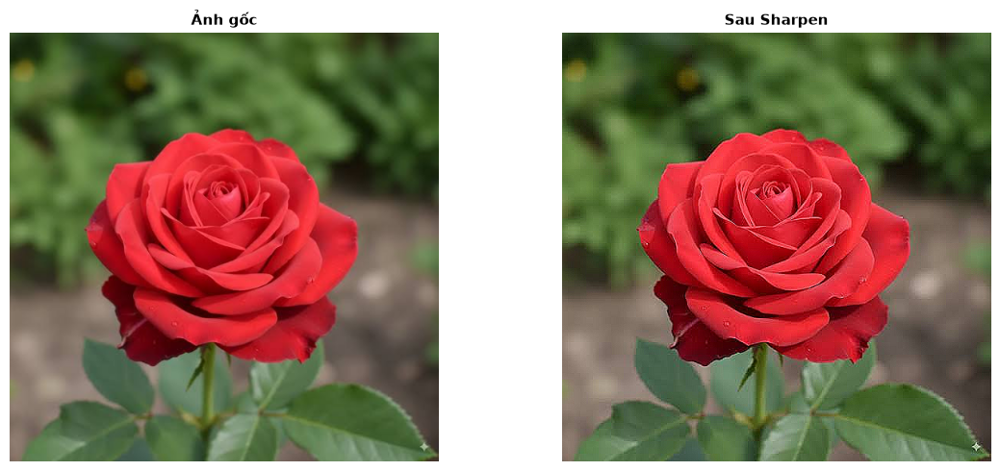

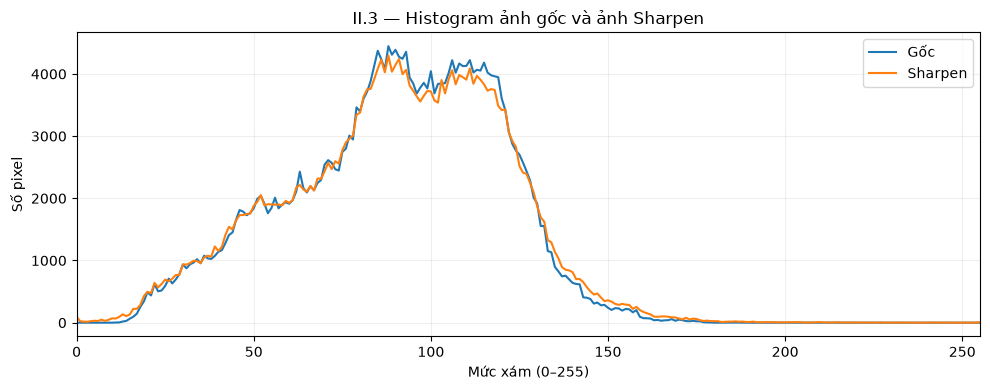

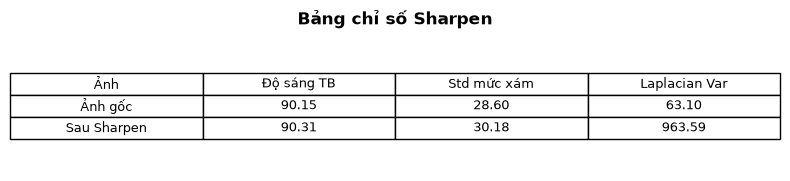

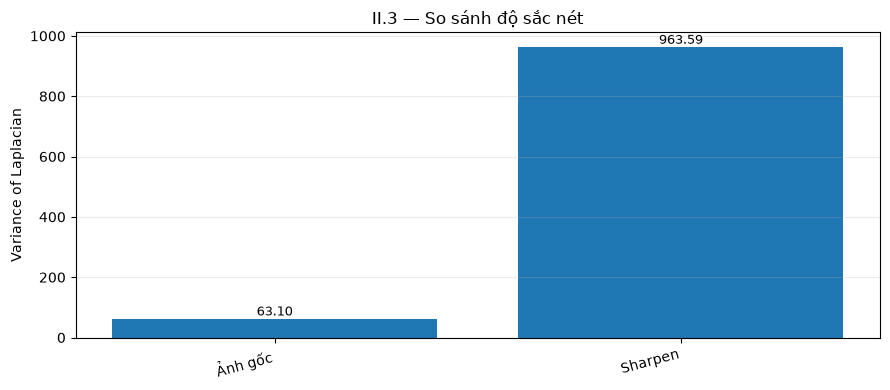

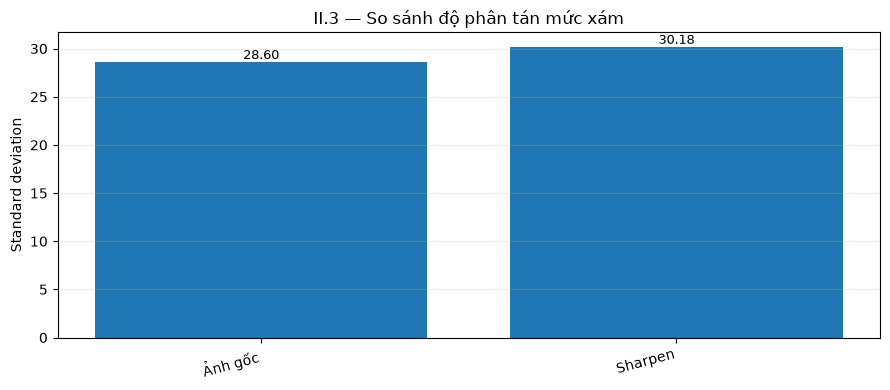

In [10]:
sharpen_kernel = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]], dtype=np.float32)
sharpen_img = cv2.filter2D(image, ddepth=-1, kernel=sharpen_kernel)
show_grid([("Ảnh gốc", image), ("Sau Sharpen", sharpen_img)], cols=2, figsize=(12, 5))
show_gray_histogram([("Gốc", image), ("Sharpen", sharpen_img)],
                    "II.3 — Histogram ảnh gốc và ảnh Sharpen")
sm0, sm1 = image_metrics(image), image_metrics(sharpen_img)
show_table(["Ảnh", "Độ sáng TB", "Std mức xám", "Laplacian Var"],
           [["Ảnh gốc", *sm0.values()], ["Sau Sharpen", *sm1.values()]],
           "Bảng chỉ số Sharpen")
plot_metric_bars(["Ảnh gốc", "Sharpen"],
                 [sm0["Độ sắc nét (Laplacian Var)"], sm1["Độ sắc nét (Laplacian Var)"]],
                 "II.3 — So sánh độ sắc nét", "Variance of Laplacian")
plot_metric_bars(["Ảnh gốc", "Sharpen"],
                 [sm0["Độ tương phản (Std)"], sm1["Độ tương phản (Std)"]],
                 "II.3 — So sánh độ phân tán mức xám", "Standard deviation")
save_img("II3_sharpen.png", sharpen_img)

**Cách nhận xét:** Sharpen thường làm tăng độ rõ của cạnh/chi tiết và có thể làm Laplacian variance tăng. Nếu chỉ số tăng quá mạnh, ảnh có thể xuất hiện viền gắt hoặc nhiễu được khuếch đại. Vì vậy cần kết hợp nhìn ảnh và đọc chỉ số, không kết luận chỉ từ một con số.

# III. BÀI TẬP NÂNG CAO

### III.1. Phát hiện cạnh bằng Sobel và Prewitt

Sobel/Prewitt tính gradient theo hai hướng X, Y. Độ lớn gradient được tính bằng `sqrt(Gx² + Gy²)`. Kết quả được chuẩn hóa để hiển thị. Biểu đồ cột bên dưới so sánh tỷ lệ pixel cạnh theo cùng một ngưỡng trên ảnh gradient đã chuẩn hóa.

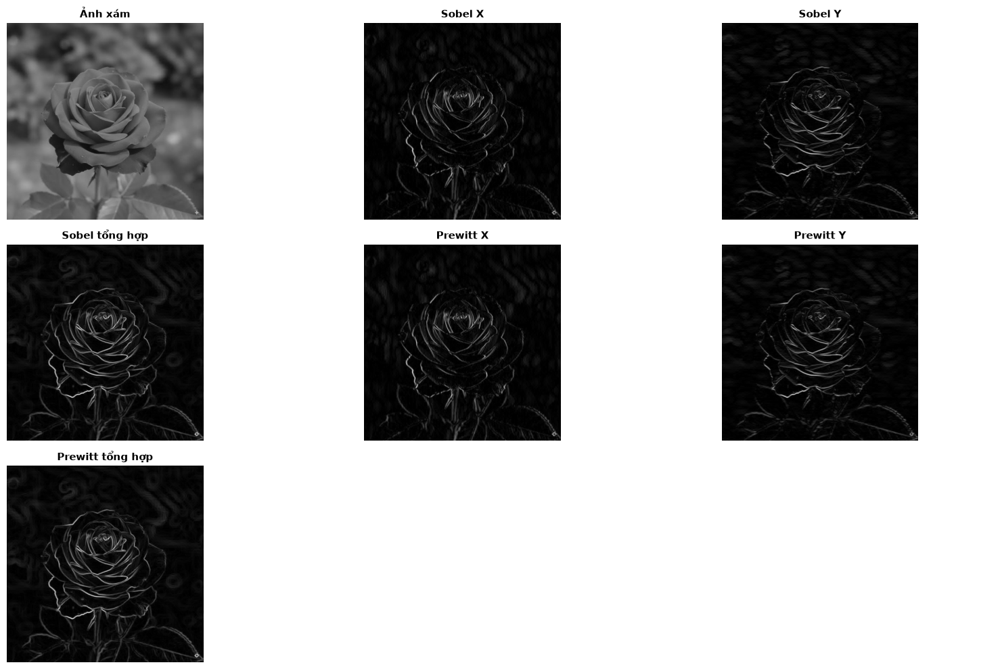

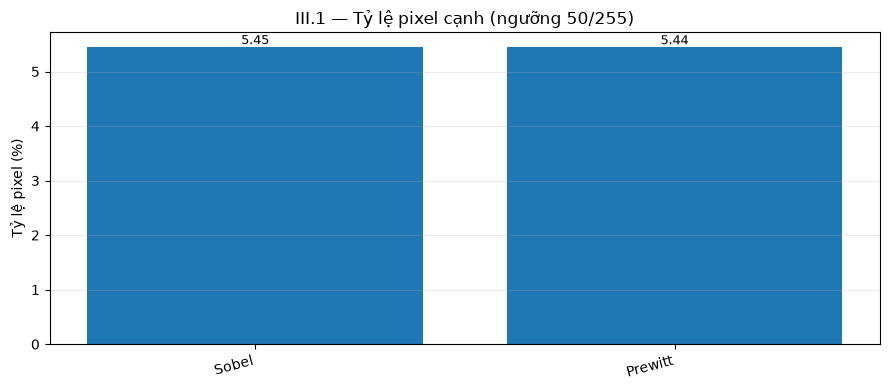

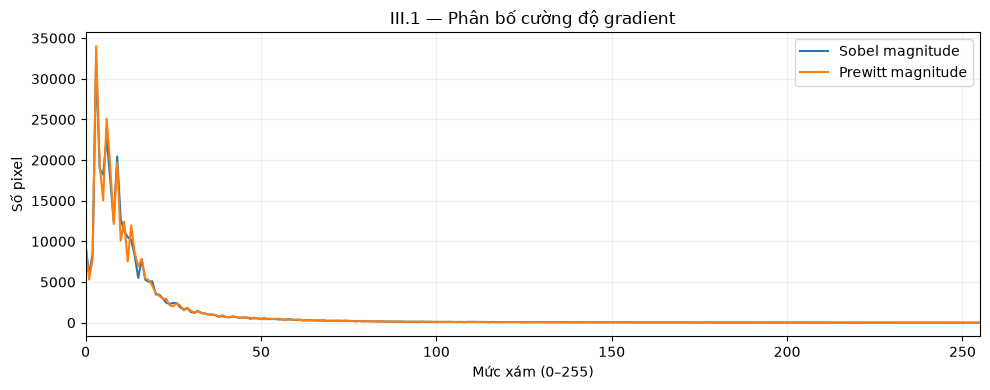

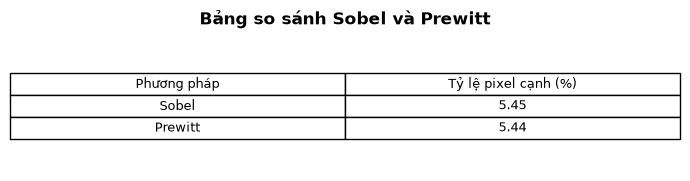

In [11]:
edge_gray = cv2.GaussianBlur(gray, (3, 3), 0)

sobel_x = cv2.Sobel(edge_gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(edge_gray, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)

prewitt_kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
prewitt_ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32)
prewitt_x = cv2.filter2D(edge_gray, cv2.CV_32F, prewitt_kx)
prewitt_y = cv2.filter2D(edge_gray, cv2.CV_32F, prewitt_ky)
prewitt_mag = cv2.magnitude(prewitt_x, prewitt_y)

def normalize_u8(arr):
    return cv2.normalize(arr, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

sobel_x_view, sobel_y_view, sobel_view = map(normalize_u8, [np.abs(sobel_x), np.abs(sobel_y), sobel_mag])
prewitt_x_view, prewitt_y_view, prewitt_view = map(normalize_u8, [np.abs(prewitt_x), np.abs(prewitt_y), prewitt_mag])

show_grid([("Ảnh xám", gray, "gray"), ("Sobel X", sobel_x_view, "gray"),
           ("Sobel Y", sobel_y_view, "gray"), ("Sobel tổng hợp", sobel_view, "gray"),
           ("Prewitt X", prewitt_x_view, "gray"), ("Prewitt Y", prewitt_y_view, "gray"),
           ("Prewitt tổng hợp", prewitt_view, "gray")],
          cols=3, figsize=(16, 10))

EDGE_THRESHOLD = 50
edge_density = {
    "Sobel": 100 * np.mean(sobel_view >= EDGE_THRESHOLD),
    "Prewitt": 100 * np.mean(prewitt_view >= EDGE_THRESHOLD)
}
plot_metric_bars(list(edge_density), list(edge_density.values()),
                 f"III.1 — Tỷ lệ pixel cạnh (ngưỡng {EDGE_THRESHOLD}/255)",
                 "Tỷ lệ pixel (%)")
show_gray_histogram([("Sobel magnitude", sobel_view), ("Prewitt magnitude", prewitt_view)],
                    "III.1 — Phân bố cường độ gradient")
show_table(["Phương pháp", "Tỷ lệ pixel cạnh (%)"],
           list(edge_density.items()), "Bảng so sánh Sobel và Prewitt")
for name, result in [("III1_sobel_x.png", sobel_x_view), ("III1_sobel_y.png", sobel_y_view),
                     ("III1_sobel.png", sobel_view), ("III1_prewitt_x.png", prewitt_x_view),
                     ("III1_prewitt_y.png", prewitt_y_view), ("III1_prewitt.png", prewitt_view)]:
    save_img(name, result)

**Cách nhận xét:** X làm nổi bật biến thiên theo chiều ngang (biên gần thẳng đứng), Y làm nổi bật biến thiên theo chiều dọc (biên gần nằm ngang). Gradient tổng hợp kết hợp hai hướng. Tỷ lệ pixel cạnh phụ thuộc ngưỡng 50/255; tỷ lệ lớn hơn không tự động có nghĩa là phát hiện tốt hơn.

### III.2. Tự thiết kế kernel

Các kernel dưới đây minh họa các hiệu ứng cơ bản: Blur, Sharpen, Edge và Emboss. Đây là các kernel tự định nghĩa, không phải thuật toán phát hiện cạnh Sobel/Prewitt.

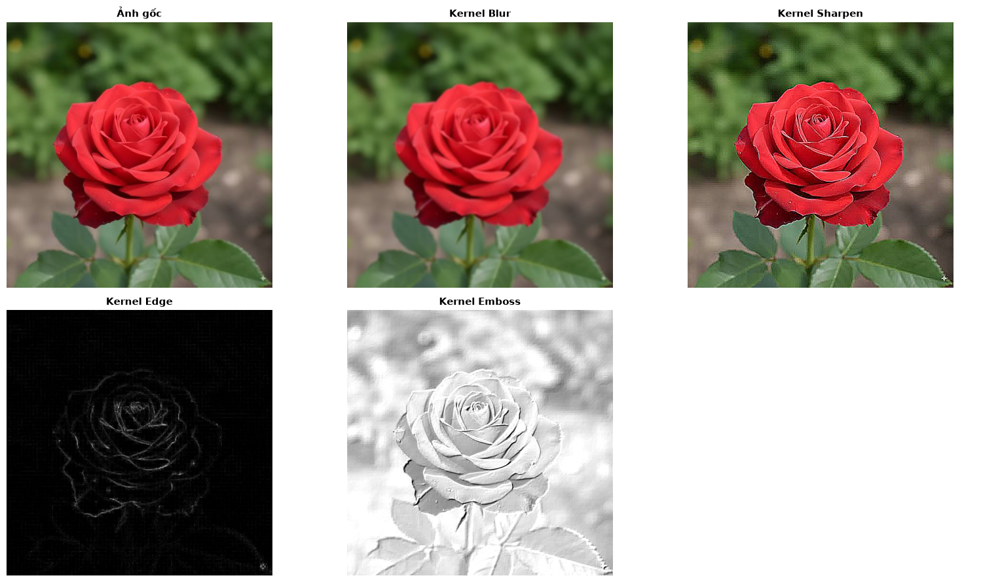

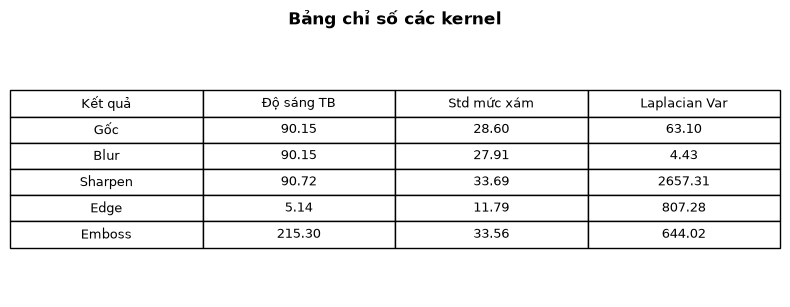

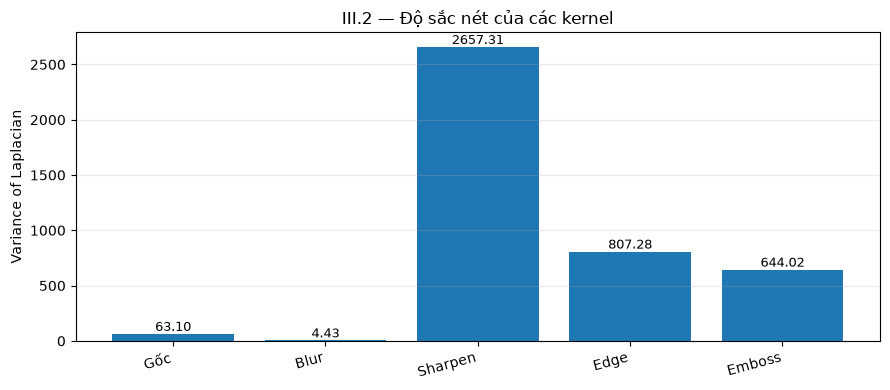

In [12]:
kernel_blur = np.ones((5, 5), np.float32) / 25
kernel_sharpen = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], np.float32)
kernel_edge = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], np.float32)
kernel_emboss = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], np.float32)

custom_blur = cv2.filter2D(image, -1, kernel_blur)
custom_sharpen = cv2.filter2D(image, -1, kernel_sharpen)
custom_edge_raw = cv2.filter2D(gray, cv2.CV_32F, kernel_edge)
custom_edge = normalize_u8(np.abs(custom_edge_raw))
custom_emboss_raw = cv2.filter2D(gray, cv2.CV_32F, kernel_emboss)
custom_emboss = np.clip(custom_emboss_raw + 128, 0, 255).astype(np.uint8)

show_grid([("Ảnh gốc", image), ("Kernel Blur", custom_blur),
           ("Kernel Sharpen", custom_sharpen), ("Kernel Edge", custom_edge, "gray"),
           ("Kernel Emboss", custom_emboss, "gray")], cols=3, figsize=(16, 9))

custom_metrics = []
for name, img in [("Gốc", image), ("Blur", custom_blur), ("Sharpen", custom_sharpen),
                  ("Edge", custom_edge), ("Emboss", custom_emboss)]:
    m = image_metrics(img)
    custom_metrics.append([name, m["Độ sáng TB"], m["Độ tương phản (Std)"],
                           m["Độ sắc nét (Laplacian Var)"]])
show_table(["Kết quả", "Độ sáng TB", "Std mức xám", "Laplacian Var"],
           custom_metrics, "Bảng chỉ số các kernel")
plot_metric_bars([row[0] for row in custom_metrics],
                 [row[3] for row in custom_metrics],
                 "III.2 — Độ sắc nét của các kernel", "Variance of Laplacian")
for name, img in [("III2_custom_blur.png", custom_blur), ("III2_custom_sharpen.png", custom_sharpen),
                  ("III2_custom_edge.png", custom_edge), ("III2_custom_emboss.png", custom_emboss)]:
    save_img(name, img)

**Cách nhận xét:** Blur làm mượt; Sharpen nhấn mạnh chi tiết; Edge làm nổi vùng thay đổi cường độ; Emboss tạo cảm giác nổi/đổ bóng. Với Edge và Emboss, các chỉ số độ sáng/độ sắc nét chỉ mô tả ảnh đầu ra, không phải thước đo chất lượng tổng quát.

### III.3. So sánh hiệu quả các loại lọc trên cùng một ảnh

Để so sánh công bằng khả năng khử nhiễu, notebook tạo **một ảnh nhiễu muối tiêu cố định** từ ảnh gốc. Mean, Gaussian, Median và Bilateral đều nhận cùng ảnh nhiễu. So sánh bằng ảnh toàn cảnh, cùng một vùng phóng to, MSE/PSNR so với ảnh gốc sạch và thời gian xử lý.

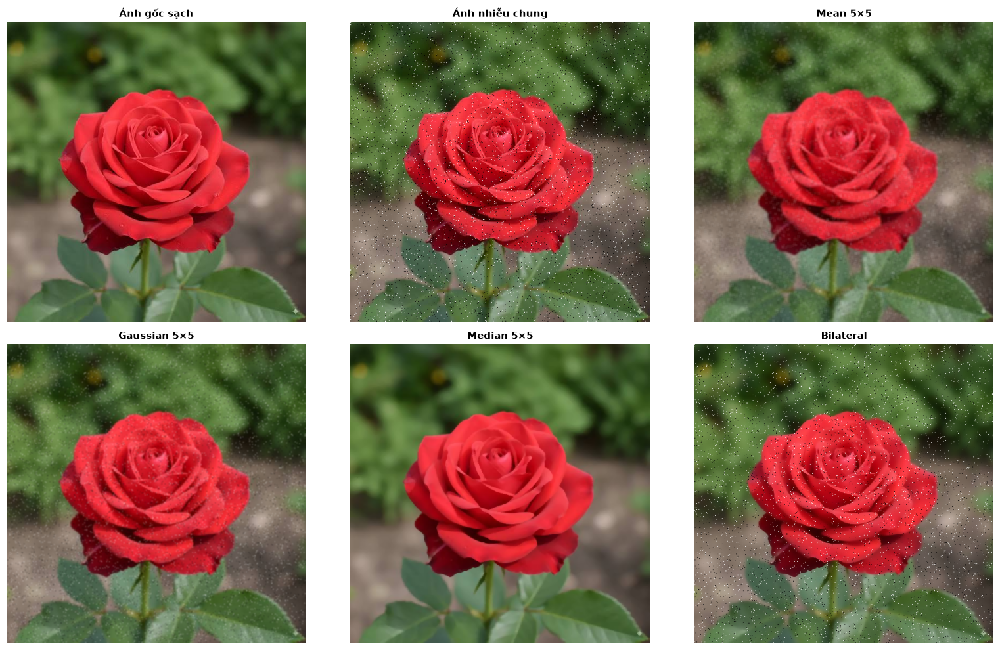

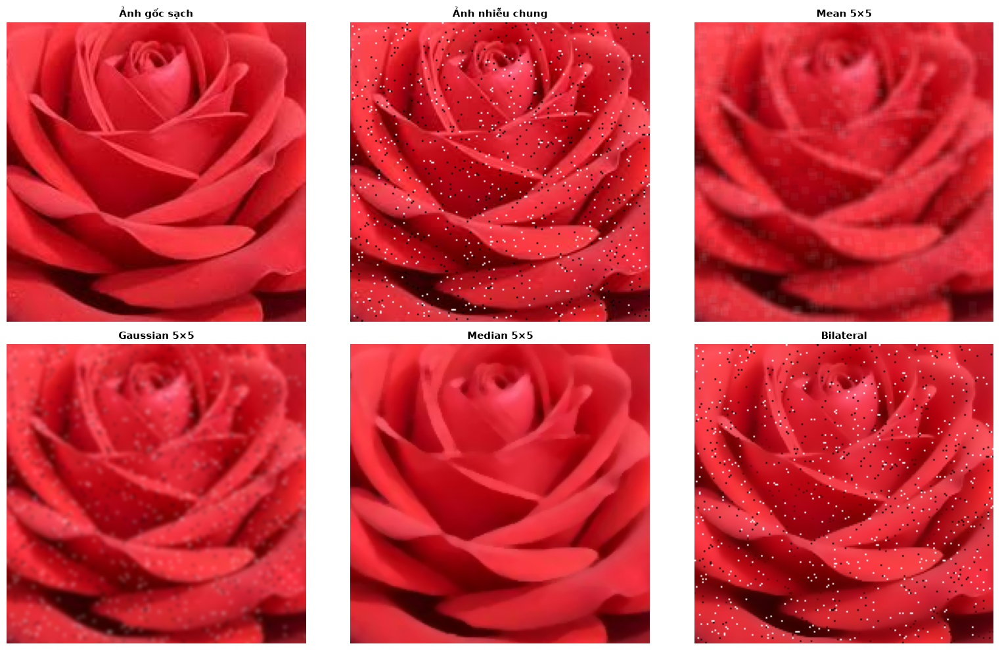

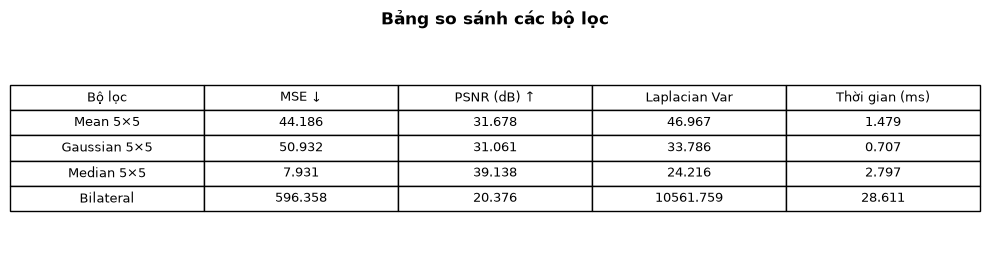

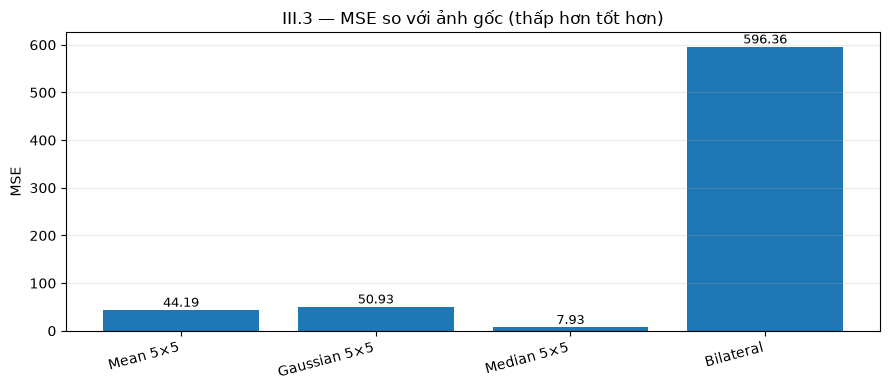

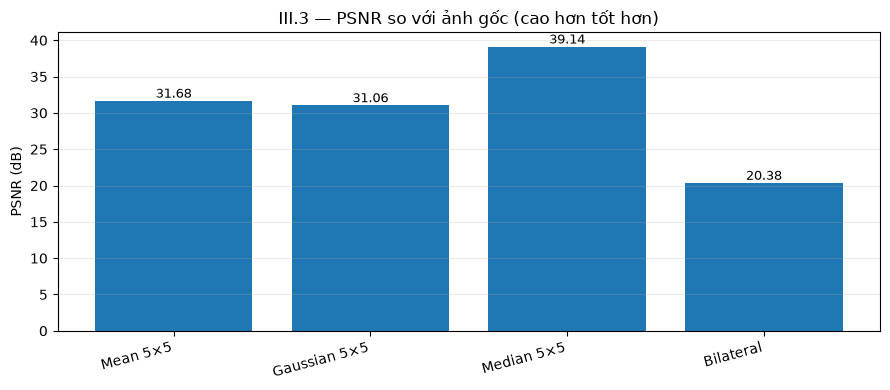

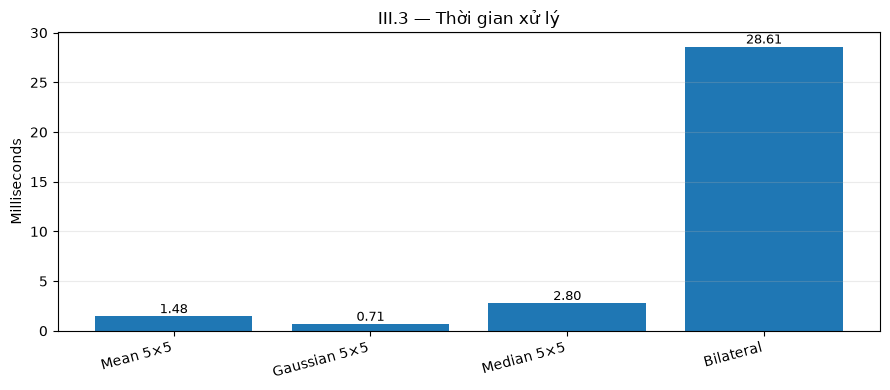

MSE thấp nhất: Median 5×5
PSNR cao nhất: Median 5×5


In [13]:
def add_salt_pepper_noise(img, amount=0.03, seed=SEED):
    """Tạo nhiễu muối tiêu tại các vị trí không trùng nhau."""
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    total = img.shape[0] * img.shape[1]
    count = min(int(amount * total), total)
    positions = rng.choice(total, size=count, replace=False)
    half = count // 2
    salt = positions[:half]
    pepper = positions[half:]
    noisy.reshape(-1, img.shape[2])[salt] = 255
    noisy.reshape(-1, img.shape[2])[pepper] = 0
    return noisy

def mse(reference, candidate):
    diff = reference.astype(np.float32) - candidate.astype(np.float32)
    return float(np.mean(diff ** 2))

def psnr(reference, candidate):
    return float(cv2.PSNR(reference, candidate))

noisy = add_salt_pepper_noise(image, amount=0.03)
filters = {
    "Mean 5×5": lambda x: cv2.blur(x, (5, 5)),
    "Gaussian 5×5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.2),
    "Median 5×5": lambda x: cv2.medianBlur(x, 5),
    "Bilateral": lambda x: cv2.bilateralFilter(x, 9, 75, 75)
}

filtered_results = {}
elapsed_ms = {}
for name, func in filters.items():
    start = time.perf_counter()
    filtered_results[name] = func(noisy)
    elapsed_ms[name] = (time.perf_counter() - start) * 1000

overview = [("Ảnh gốc sạch", image), ("Ảnh nhiễu chung", noisy)]
overview += list(filtered_results.items())
show_grid(overview, cols=3, figsize=(16, 10))

# Phóng to đúng cùng tọa độ vùng giữa cho mọi kết quả.
h, w = gray.shape
ch, cw = max(1, int(h * 0.35)), max(1, int(w * 0.35))
y0, x0 = (h - ch)//2, (w - cw)//2
def crop_center(img):
    return img[y0:y0+ch, x0:x0+cw]
crop_items = [(name, crop_center(img)) for name, img in overview]
show_grid(crop_items, cols=3, figsize=(16, 10))

comparison_rows = []
for name, result in filtered_results.items():
    comparison_rows.append([name, mse(image, result), psnr(image, result),
                            image_metrics(result)["Độ sắc nét (Laplacian Var)"],
                            elapsed_ms[name]])
show_table(["Bộ lọc", "MSE ↓", "PSNR (dB) ↑", "Laplacian Var", "Thời gian (ms)"],
           comparison_rows, "Bảng so sánh các bộ lọc", decimals=3)

plot_metric_bars([row[0] for row in comparison_rows], [row[1] for row in comparison_rows],
                 "III.3 — MSE so với ảnh gốc (thấp hơn tốt hơn)", "MSE")
plot_metric_bars([row[0] for row in comparison_rows], [row[2] for row in comparison_rows],
                 "III.3 — PSNR so với ảnh gốc (cao hơn tốt hơn)", "PSNR (dB)")
plot_metric_bars([row[0] for row in comparison_rows], [row[4] for row in comparison_rows],
                 "III.3 — Thời gian xử lý", "Milliseconds")

best_mse_name = min(comparison_rows, key=lambda row: row[1])[0]
best_psnr_name = max(comparison_rows, key=lambda row: row[2])[0]
print(f"MSE thấp nhất: {best_mse_name}")
print(f"PSNR cao nhất: {best_psnr_name}")
for name, result in [("III3_anh_nhieu.png", noisy), *[(f"III3_{k.lower().replace(' ','_').replace('×','x')}.png", v)
                                                       for k, v in filtered_results.items()]]:
    save_img(name, result)

**Cách nhận xét:** MSE thấp hơn và PSNR cao hơn nghĩa là kết quả gần ảnh gốc sạch hơn theo sai số pixel. Median thường phù hợp với nhiễu muối tiêu; Bilateral cố gắng làm mượt nhưng giữ biên; Mean/Gaussian làm mượt nhưng có thể làm nhòe biên. Kết luận cuối cùng phải kết hợp bảng số liệu và vùng ảnh phóng to. Thời gian chạy phụ thuộc kích thước ảnh và máy tính.

### III.4. Tìm hiểu lọc phi tuyến tính: Median và Bilateral

Mục này tách riêng hai bộ lọc phi tuyến tính theo đúng đề bài. Dùng cùng ảnh nhiễu đã tạo ở III.3 để quan sát tác dụng và so sánh trực tiếp.

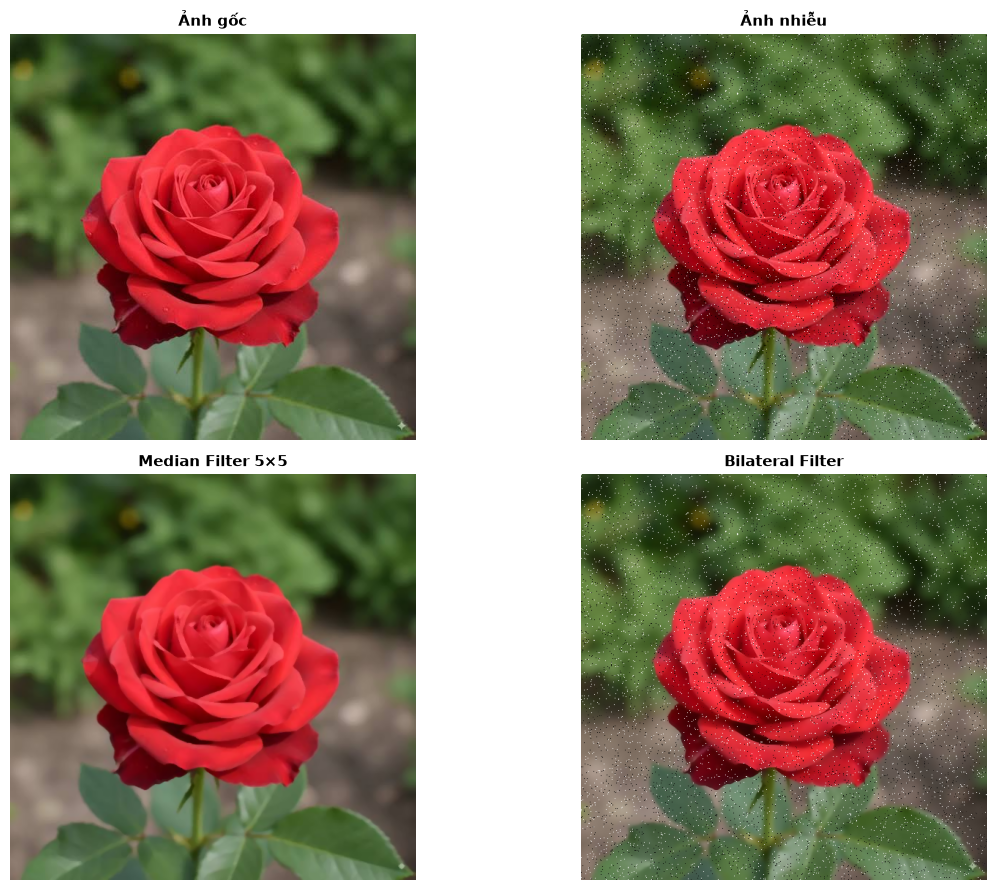

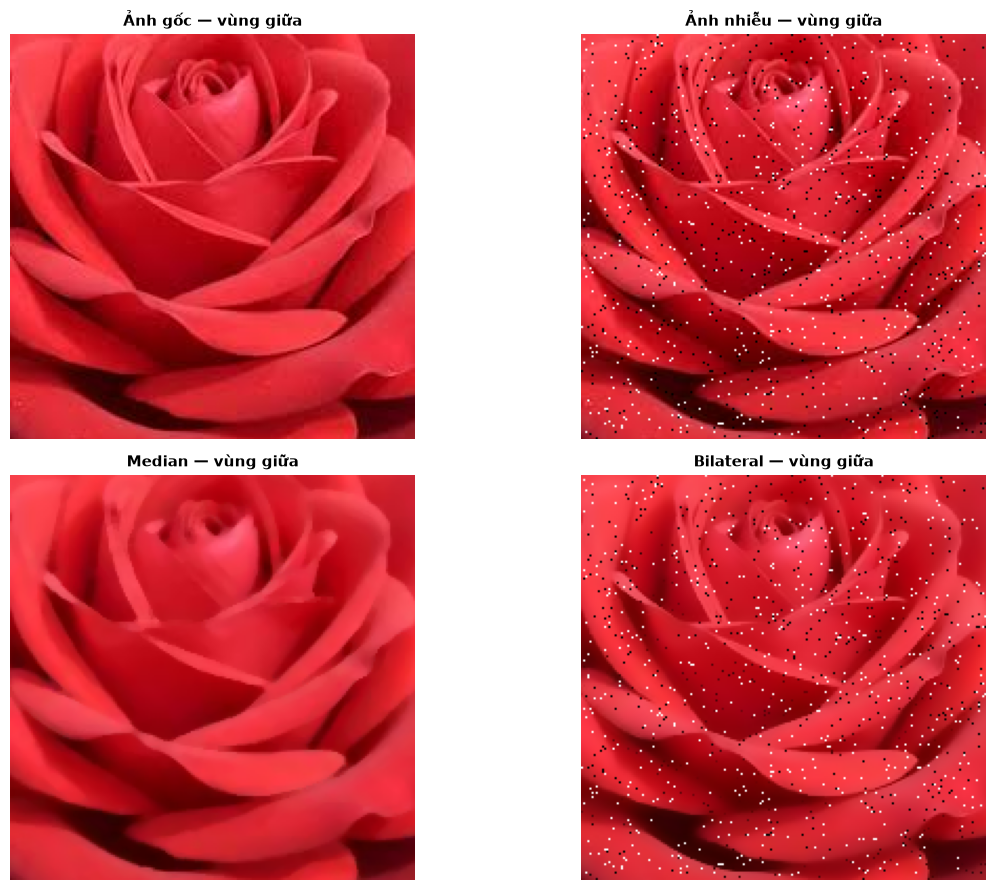

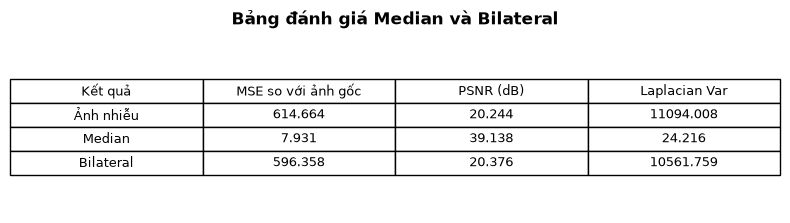

In [14]:
median_result = filtered_results["Median 5×5"]
bilateral_result = filtered_results["Bilateral"]
show_grid([("Ảnh gốc", image), ("Ảnh nhiễu", noisy),
           ("Median Filter 5×5", median_result),
           ("Bilateral Filter", bilateral_result)],
          cols=2, figsize=(13, 9))
show_grid([("Ảnh gốc — vùng giữa", crop_center(image)),
           ("Ảnh nhiễu — vùng giữa", crop_center(noisy)),
           ("Median — vùng giữa", crop_center(median_result)),
           ("Bilateral — vùng giữa", crop_center(bilateral_result))],
          cols=2, figsize=(13, 9))

nonlinear_rows = []
for name, img in [("Ảnh nhiễu", noisy), ("Median", median_result), ("Bilateral", bilateral_result)]:
    nonlinear_rows.append([name, mse(image, img), psnr(image, img),
                           image_metrics(img)["Độ sắc nét (Laplacian Var)"]])
show_table(["Kết quả", "MSE so với ảnh gốc", "PSNR (dB)", "Laplacian Var"],
           nonlinear_rows, "Bảng đánh giá Median và Bilateral", decimals=3)

**Cách nhận xét:** Median thay pixel bằng trung vị trong cửa sổ, thường loại bỏ tốt các điểm nhiễu đen/trắng. Bilateral kết hợp khoảng cách không gian và độ gần về cường độ, nhờ đó có xu hướng giữ biên tốt hơn bộ lọc làm mượt thông thường. So sánh ảnh phóng to để nhận xét chi tiết nào còn được giữ lại.

## 4. Kiểm tra và tổng kết kết quả

Cell cuối kiểm tra kích thước, kiểu dữ liệu và lưu các ảnh đầu ra. Các hình/biểu đồ hiển thị trong từng mục cũng được lưu dưới dạng ảnh kết quả khi phù hợp.

In [15]:
results_to_check = {
    "brightness_up": bright, "brightness_down": dark,
    "contrast_up": contrast_up, "contrast_down": contrast_down,
    "negative": negative, "threshold": binary,
    "mean": mean_img, "gaussian": gaussian_img, "sharpen": sharpen_img,
    "sobel": sobel_view, "prewitt": prewitt_view,
    "custom_blur": custom_blur, "custom_sharpen": custom_sharpen,
    "custom_edge": custom_edge, "custom_emboss": custom_emboss,
    "noisy": noisy, **{f"filter_{k}": v for k, v in filtered_results.items()}
}
for name, result in results_to_check.items():
    assert result.shape[:2] == image.shape[:2], f"Sai kích thước: {name}"
    assert result.dtype == np.uint8, f"Sai kiểu dữ liệu: {name}"
    assert result.min() >= 0 and result.max() <= 255, f"Sai miền pixel: {name}"

saved = sorted(p.name for p in OUTPUT_DIR.glob("*.png"))
print("KIỂM TRA THÀNH CÔNG")
print("Ảnh đầu vào:", image_path.name, f"({width} x {height})")
print("Số kết quả được kiểm tra:", len(results_to_check))
print("Số ảnh kết quả đã lưu:", len(saved))
print("Thư mục lưu:", OUTPUT_DIR.resolve())

KIỂM TRA THÀNH CÔNG
Ảnh đầu vào: images.jpg (554 x 554)
Số kết quả được kiểm tra: 20
Số ảnh kết quả đã lưu: 49
Thư mục lưu: D:\python\Computer Vision\lab2\results
